### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import seaborn as sns

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [4]:
# Load the csv file into a DataFrame
data = pd.read_csv('data/coupons.csv')

In [5]:
# Preview the data
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [6]:
# Inspect column names, data types, and non-null counts
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [7]:
# Count missing values per column for columns that have null
missing_data = data.isnull().sum()
missing_data[missing_data > 0].sort_values(ascending=False)

car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
dtype: int64

In [8]:
# Check which values each column with missing data contains,
# so nulls can be filled with a meaningful category
missing_columns = ['car', 'CoffeeHouse', 'Restaurant20To50', 'CarryAway', 'RestaurantLessThan20', 'Bar']
for i in missing_columns:
    print(f"{i}: {data[i].unique()}")

car: [nan 'Scooter and motorcycle' 'crossover' 'Mazda5' 'do not drive'
 'Car that is too old to install Onstar :D']
CoffeeHouse: ['never' 'less1' '4~8' '1~3' 'gt8' nan]
Restaurant20To50: ['1~3' 'less1' 'never' 'gt8' '4~8' nan]
CarryAway: [nan '4~8' '1~3' 'gt8' 'less1' 'never']
RestaurantLessThan20: ['4~8' '1~3' 'less1' 'gt8' nan 'never']
Bar: ['never' 'less1' '1~3' 'gt8' nan '4~8']


3. Decide what to do about your missing data -- drop, replace, other...

 The missing data is in columns are what car the person drives, and then how often the person frequents locations. I think leaving NaN in the car column is fine but I am going to replace the NaN entries with never in the columns that describe location frequency.

In [9]:
# Frequency columns are categorical, so treat missing responses as "never"
missing_columns = ['CoffeeHouse', 'Restaurant20To50', 'CarryAway', 'RestaurantLessThan20', 'Bar']
data[missing_columns] = data[missing_columns].fillna('never')

# Confirm that only the car column still contains missing values
missing_data = data.isnull().sum()
missing_data[missing_data > 0].sort_values(ascending=False)

car    12576
dtype: int64

4. What proportion of the total observations chose to accept the coupon?



In [10]:
# Since Y is 1 for acceptance and 0 otherwise, its mean is the acceptance rate, we multiply by 100 to get the percentage of accepted coupons.
# We also print the total number of accepted coupons and the total number of coupons in the dataset.
accepted_proportion = data["Y"].mean()
print(f"Proportion of accepted coupons: {accepted_proportion * 100:.2f}%"
      f"\nThat's {data['Y'].sum()} accepted coupons out of {len(data)} total coupons.")

Proportion of accepted coupons: 56.84%
That's 7210 accepted coupons out of 12684 total coupons.


5. Use a bar plot to visualize the `coupon` column.

We can see that most of the coupons in our data are for Coffee Houses

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'Coffee House'),
  Text(1, 0, 'Restaurant(<20)'),
  Text(2, 0, 'Carry out & Take away'),
  Text(3, 0, 'Bar'),
  Text(4, 0, 'Restaurant(20-50)')])

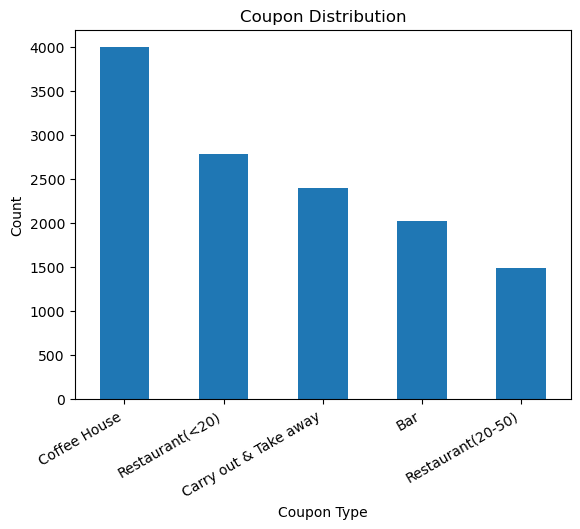

In [11]:
# Compare how many coupons of each type were offered
data["coupon"].value_counts().plot(kind='bar', title='Coupon Distribution', xlabel='Coupon Type', ylabel='Count')

# Rotate x-axis labels
plt.xticks(rotation=30, ha='right')

6. Use a histogram to visualize the temperature column.

<Axes: xlabel='temperature', ylabel='Count'>

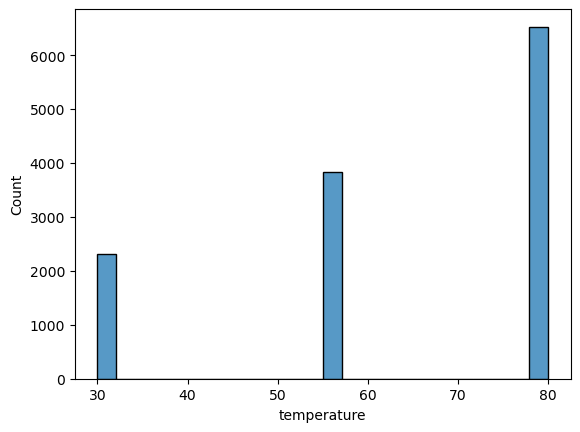

In [12]:
# Temperature has only three values (30, 55, 80), so this shows how often each occurs
sns.histplot(data=data, x = "temperature")

Temperature barplot not that interesting because there are only 3 values in that column: 30, 55, and 80

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [13]:
# Subset the data to only bar coupon offers
Bar = data[data["coupon"] == "Bar"]

2. What proportion of bar coupons were accepted?


In [14]:
# Acceptance rate among drivers who received a bar coupon
accepted_bar = Bar["Y"].mean()
print(f"Proportion of accepted coupons: {accepted_bar * 100:.2f}%"
      f"\nThat's {Bar['Y'].sum()} accepted coupons out of {len(Bar)} total coupons.")

Proportion of accepted coupons: 41.00%
That's 827 accepted coupons out of 2017 total coupons.


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [15]:
# Split bar coupon recipients into 3 or fewer visits/month more than 3 
bar_most_3 = Bar[Bar["Bar"].isin(["never", "less1", "1~3"])]
bar_more_3 = Bar[Bar["Bar"].isin(["4~8", "gt8"])]

# Compare acceptance rates between the two groups
bar_more_3_AR = bar_more_3["Y"].mean()
bar_most_3_AR = bar_most_3["Y"].mean()
bar_AR_diff =  bar_more_3_AR - bar_most_3_AR

print(f"Acceptance rate for bars with 3 or fewer purchases: {bar_most_3_AR*100:.2f}%")
print(f"Acceptance rate for bars with more than 3 purchases: {bar_more_3_AR*100:.2f}%")
print(f"Difference in acceptance rates: {bar_AR_diff*100:.2f}%")

Acceptance rate for bars with 3 or fewer purchases: 37.07%
Acceptance rate for bars with more than 3 purchases: 76.88%
Difference in acceptance rates: 39.81%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [16]:
# Group drivers who visit bars more than once a month and are over age 25
bar_morethan1_over25 = Bar[(~Bar["age"].isin(["21","below21", "25"])) & (~Bar["Bar"].isin(["never", "less1"]))]

# and the group for all the others 
bar_all_others = Bar[(Bar["age"].isin(["21","below21", "25"])) | (Bar["Bar"].isin(["never", "less1"]))]

# Compare acceptance rates between the two groups
bar_morethan1_over25_AR = bar_morethan1_over25["Y"].mean()
bar_all_others_AR = bar_all_others["Y"].mean()
bar_AR_diff2 = bar_morethan1_over25_AR - bar_all_others_AR

print(f"Acceptance rate for bars with more than 1 purchase and age over 25: {bar_morethan1_over25_AR*100:.2f}%")
print(f"Acceptance rate for all other bars: {bar_all_others_AR*100:.2f}%")
print(f"Difference in acceptance rates: {bar_AR_diff2*100:.2f}%")

Acceptance rate for bars with more than 1 purchase and age over 25: 69.52%
Acceptance rate for all other bars: 33.50%
Difference in acceptance rates: 36.02%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [17]:
# Drivers who visit bars more than once a month, have no kids in the car,
# and do not work in farming, fishing, or forestry
more_than_1_no_kids_no_farm = Bar[(Bar["Bar"].isin(["1~3", "4~8", "gt8"])) & 
    (Bar["passanger"] != "Kid(s)") &
    (Bar["occupation"] != "Farming Fishing & Forestry")]

# and the group for all the others 
bar_all_others2 = Bar[(~Bar["Bar"].isin(["1~3", "4~8", "gt8"])) |
    (Bar["passanger"] == "Kid(s)") |
    (Bar["occupation"] == "Farming Fishing & Forestry")]

# Compare acceptance rates between the two groups
more_than_1_no_kids_no_farm_AR = more_than_1_no_kids_no_farm["Y"].mean()
bar_all_others2_AR = bar_all_others2["Y"].mean()
bar_AR_diff3 = more_than_1_no_kids_no_farm_AR - bar_all_others2_AR

print(f"Acceptance rate for bars with more than 1 purchase, no kids, and not in farming/fishing/forestry: {more_than_1_no_kids_no_farm_AR*100:.2f}%")
print(f"Acceptance rate for all other bars: {bar_all_others2_AR*100:.2f}%")
print(f"Difference in acceptance rates: {bar_AR_diff3*100:.2f}%")

Acceptance rate for bars with more than 1 purchase, no kids, and not in farming/fishing/forestry: 71.32%
Acceptance rate for all other bars: 29.60%
Difference in acceptance rates: 41.72%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [18]:
# Group A: bar >1/month, passengers not kids, not widowed
groupA = Bar[(Bar["Bar"].isin(["1~3", "4~8", "gt8"])) &
                (Bar["passanger"] != "Kid(s)") &
                (Bar["maritalStatus"] != "Widowed")]

# Group B: bar >1/month, under age 30
groupB = Bar[(Bar["Bar"].isin(["1~3", "4~8", "gt8"])) &
                (Bar["age"].isin(["21", "26"]))]

# Group C: cheap restaurants >4/month, income <$50K
groupC = Bar[(Bar["RestaurantLessThan20"].isin(["4~8", "gt8"])) &
                (Bar["income"].isin(["Less than $12500", "$12500 - $24999", "$25000 - $37499", "$37500 - $49999"]))]

# Combine all three groups
combined = pd.concat([groupA, groupB, groupC]).drop_duplicates()

# Everyone else
all_others = Bar[~Bar.index.isin(combined.index)]

# Acceptance rate (AR) for each group, the combined group, and all others
groupA_AR = np.round(groupA["Y"].mean()*100, 2)
groupB_AR = np.round(groupB["Y"].mean()*100, 2)
groupC_AR = np.round(groupC["Y"].mean()*100, 2)
combined_AR = np.round(combined["Y"].mean()*100, 2)
all_others3_AR = np.round(all_others["Y"].mean()*100, 2)

print("Group A (bar >1/month, no kids, not widowed):", groupA_AR, "%")
print("Group B (bar >1/month, under 30):", groupB_AR, "%")
print("Group C (cheap restaurants >4/month, income <$50K):", groupC_AR, "%")
print("Combined (any of A/B/C):", combined_AR, "%")
print("All other bar coupon drivers:", all_others3_AR, "%")
print("Difference:", np.round(combined_AR - all_others3_AR, 2), "%")

Group A (bar >1/month, no kids, not widowed): 71.32 %
Group B (bar >1/month, under 30): 73.13 %
Group C (cheap restaurants >4/month, income <$50K): 45.35 %
Combined (any of A/B/C): 58.89 %
All other bar coupon drivers: 29.81 %
Difference: 29.08 %


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on my observations from problems 3 through 6, I believe that the kind of driver who accepts bar coupons is someone who already goes to bars fairly regularly. I noticed that drivers who go to bars more than once a month accepted bar coupons at a much higher rate than those who don't (around 71% compared to 30% for everyone else). This is a large difference and suggests that frequency of going to the bar is a key factor.

I also observed that younger drivers were more likely to accept bar coupons. Drivers who go to bars more than once a month and are under 30 had a 73% acceptance rate, which is the highest I saw across any group. This makes some sense to me, since younger drivers may be more open to going to a bar on short notice than older drivers. The third group I looked at was drivers who go to cheap restaurants often and have lower incomes, and their acceptance rate was only around 45%. This is a smaller jump from the overall bar average of 41%, so I think restaurant habits and income level don't predict bar coupon acceptance nearly as well as frequency of going to the bar and age do.

A key observation from my analysis is that having kids in the car makes a noticeable difference. When kids were present, acceptance dropped significantly. The same goes for being widowed. This suggests to me that bar coupon acceptance is tied to lifestyle and social freedom. People who are younger, socialize at bars already, and don't have kids seem the ones most likely to say yes to a bar coupon.

## Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

#### Im going to analyze the Coffee house coupon group
My first step is going to be making a dataframe coffee dataframe and check the acceptance rate of this group

In [19]:
# Subset to coffee house coupons and compute acceptance rate
Coffee = data[data["coupon"] == "Coffee House"]
Coffee_AR = Coffee["Y"].mean()
print(f"Acceptance rate for Coffee House coupons: {Coffee_AR:.2%}")

Acceptance rate for Coffee House coupons: 49.92%


Initially I think that people are more likely to accept a coupon if it's in the morning time, let's see:

In [20]:
# Compare acceptance in the morning (6AM and 10AM) against other times
coffee_morning_AR = Coffee[Coffee["time"].isin(["6AM","10AM"])]["Y"].mean()
coffee_other = Coffee[~Coffee["time"].isin(["6AM","10AM"])]["Y"].mean()
print(f"Acceptance rate for Coffee House coupons in the morning (6AM and 10AM): {coffee_morning_AR:.2%}")
print(f"Acceptance rate for Coffee House coupons at other times: {coffee_other:.2%}")

Acceptance rate for Coffee House coupons in the morning (6AM and 10AM): 64.07%
Acceptance rate for Coffee House coupons at other times: 45.82%


We see a 14 percent increase of coffee house coupon acceptance when it was morning and a drop in 3 percent when not in the morning, let's practice using graphs to get more info:

<Axes: xlabel='Y', ylabel='time'>

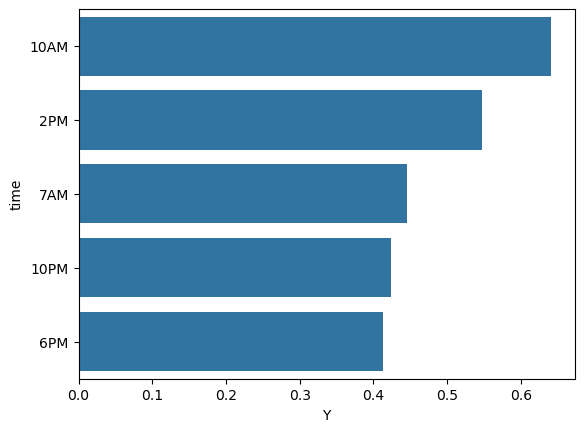

In [21]:
# Bar plot of acceptance rate by time of day, sorted from highest to lowest
sns.barplot(data = Coffee, 
            x = "Y", y = "time", 
            order = Coffee.groupby("time")["Y"].mean().sort_values(ascending=False).index,
            errorbar=None)

Interesting discovery here, initial assumption of morning being most populat time isn't the best description. In reality, it's times close to noon that show the largest acceptance rate. One guess to explain why 7am is so much lower than 10am is that people may be making coffee at home, and get coffee around midday when they are working. 

### Let's check occupation and age
#### First occupation:

<Axes: xlabel='Y', ylabel='occupation'>

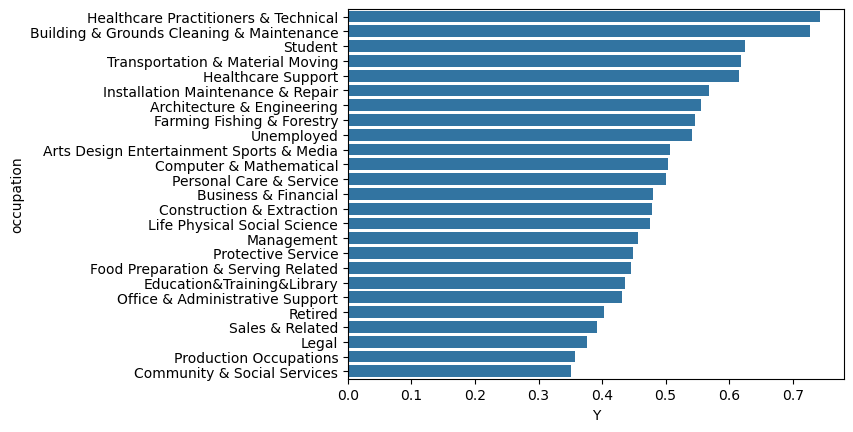

In [22]:
# Same comparison for occupation
sns.barplot(data = Coffee, 
            x = "Y", y = "occupation", 
            order = Coffee.groupby("occupation")["Y"].mean().sort_values(ascending=False).index,
            errorbar=None)

#### Now age:

<Axes: xlabel='Y', ylabel='age'>

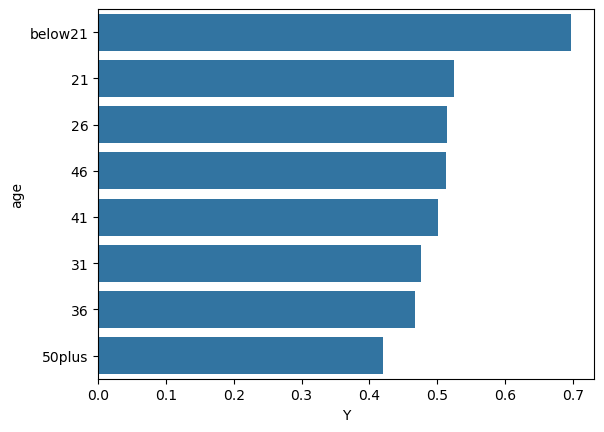

In [23]:
# Same comparison for age group
sns.barplot(data = Coffee, 
            x = "Y", y = "age", 
            order = Coffee.groupby("age")["Y"].mean().sort_values(ascending=False).index,
            errorbar=None)

#### Initial Observations
Now we can see that the younger someone is, the more likely the customer will accept the coupon. Additionally, morning to early afternoon times are most popular times. Lastly, students, healthcare professionals, and blue collar workers are more likely to accept coupons for coffee in our dataset.

#### Investigate a few more set of features:

C:\Users\haata\AppData\Local\Temp\ipykernel_73540\2083646343.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Coffee['temperature'] = Coffee['temperature'].astype(str)


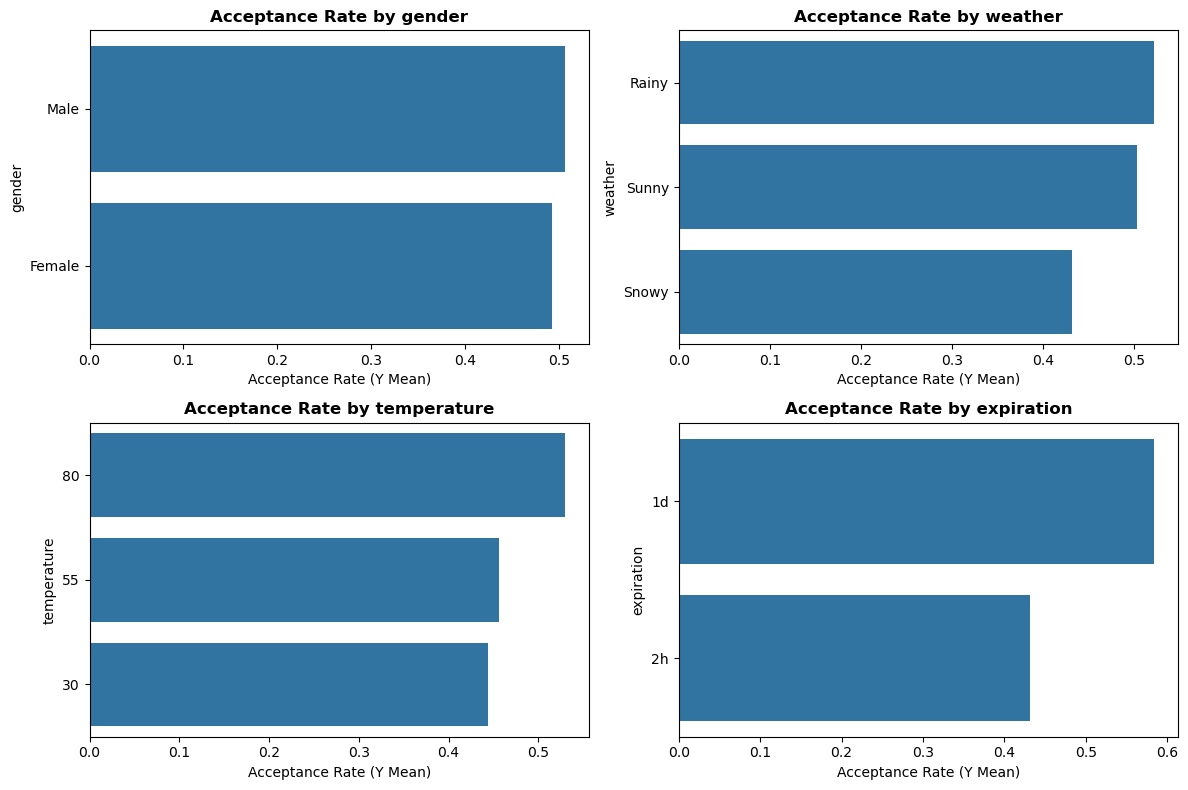

In [24]:
# Columns to investigate in a 2x2 grid of plots
groups = ['gender', 'weather', 'temperature', 'expiration']

# Temperature is numeric with only three values (30, 55, 80)
# convert to string so it is treated as a category
Coffee['temperature'] = Coffee['temperature'].astype(str)

# Create a 2x2 grid of plots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# Flatten the 2D array of axes so it can be looped over easily
axes = axes.flatten()


for i, col in enumerate(groups):
    ax = axes[i]

    # Sort categories by mean acceptance rate
    sorted_order = Coffee.groupby(col)["Y"].mean().sort_values(ascending=False).index

    # Plot the acceptance rate
    sns.barplot(
        data=Coffee, 
        x="Y", 
        y=col, 
        order=sorted_order,
        errorbar=None,
        ax=ax,
    )

    # Label each subplot
    ax.set_title(f'Acceptance Rate by {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Acceptance Rate (Y Mean)', fontsize=10)
    ax.set_ylabel(col, fontsize=10)

# Prevent titles and labels from overlapping
plt.tight_layout()
plt.show()

# Final Conclusion
Seeing all of the data and visualizing with the seaborn library's barplot, we can create decent assumptions of demographic behaviors of people who are more likely to accept a coupon for coffee houses. One surprising event in the data is that rainy and sunny days have nearly identical acceptance rate responses. This could be that while I associate coffee houses with hot drinks, within the last few decades, including more cold drinks such as cold coffee, tea, and "refreshers" must be bringing customers in for cold drinks as well. This conclusion is further supported by the relationship the temperature and the data, when the temperatures are the hotter, people are actually more likely to accept coupons for coffe houses. 

Some additional notes were that gender doesn't have play a strong influence, which was surprising to me. Acceptance rate was another group I looked at, which the outcome made sense, it concludes that longer expiration time leads to a higher acceptance rate. This could be because people are more likely to use the coupon if it fits better in their schedule, 2 hours is fairly soon and people may not have the time for it. Lastly, occupation and age had great influence on accptance rate, with younger recipients, nurses, students, and blue collar jobs with a high acceptance rate. Office jobs noteably aren't high and I think this is related to why older people might not have as high of an acceptance rate. My hypothesis is that people who are older are more likely to have more stationary admin roles and are likely to have access to drinks in their office or maybe just are not interested in going out for drinks as other groups.